# MIRA-Bench Mixed Prompt Agent Evaluation

Run the MMEdit agent on MIRA-Bench with the mixed-modality instruction and selected visual prompts. The dataset is a file-based Hugging Face snapshot, so setup downloads its benchmark images and uses them to resolve the local image references in the annotations. There are no target images. By default, this notebook processes every annotation; set `SAMPLE_LIMIT = 1` for a smoke test. Set `RESUME_LAST_RUN = True` to continue the latest run, skipping completed samples and retrying failed ones.

Install with `uv sync --extra models --extra benchmark`. Annotation records are loaded from the latest `.out/annotation/mira_bench/run_*/mira_bench_mixed.jsonl`; if no canonical run exists, the latest legacy `.out/annotation/mirage/run_*/mirage_mixed.jsonl` is used. Override the run with `MMEDIT_MIRA_BENCH_ANNOTATION_RUN=run_<timestamp>` or the file with `MMEDIT_MIRA_BENCH_ANNOTATIONS`. Configure `MMEDIT_API_KEY` or `GOOGLE_API_KEY`.

Results are saved under `.out/evaluation/mira_bench/mixed/run_<timestamp>/`.

In [1]:
import os

from huggingface_hub import snapshot_download
import matplotlib.pyplot as plt
from evaluation.notebook import create_run_directory, load_benchmark
from evaluation.common import annotate_sample, load_sample, run_benchmark, select_reference_prompts

DATASET_ID = "ziqiangoodgood/MIRAGE"
DATASET_SNAPSHOT = snapshot_download(
    repo_id=DATASET_ID,
    repo_type="dataset",
    allow_patterns=["benchmark/*.jpg", "benchmark/*.jpeg", "benchmark/*.png", "benchmark/*.webp"],
)
os.environ["MIRA_BENCH_IMAGE_ROOT"] = os.path.join(DATASET_SNAPSHOT, "benchmark")

BENCHMARK = "mira_bench"
PROMPT_MODE = "mixed"
context = load_benchmark(BENCHMARK, prompt_mode=PROMPT_MODE)
ANNOTATION_FILE = context.annotation_file
OUTPUT_ROOT = context.output_dir
records = context.records
image_loader = context.image_loader
print(f"{len(records)} MIRA-Bench annotations loaded from {ANNOTATION_FILE}")
print("Fields:", sorted(records[0]))

/Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 600 files: 100%|██████████| 600/600 [00:00<00:00, 8477.91it/s]

4 MIRA-Bench annotations loaded from /Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.out/annotation/mira_bench/run_20261017_153758_826510/mira_bench_mixed.jsonl
Fields: ['benchmark', 'linguistic_stats', 'metadata', 'mixed_instruction', 'original_instruction', 'parser_instruction', 'references', 'sample_id', 'source_ref', 'split', 'target_ref', 'validation']


mirage:4.jpg Change the texture of <box_0> to rough, and remove <box_1>, and change the material of <box_2> to wood, and change the color of <box_3> to yellow, and remove <box_4>.
Reference selectors: [{'token': '<box_0>', 'variable': 'box_0', 'refers_to': 'the left bucket', 'box': [128.0, 483.0, 365.0, 753.0], 'point': None, 'scribble': False}, {'token': '<box_1>', 'variable': 'box_1', 'refers_to': 'the middle bucket', 'box': [389.0, 482.0, 628.0, 751.0], 'point': None, 'scribble': False}, {'token': '<box_2>', 'variable': 'box_2', 'refers_to': 'the right bucket', 'box': [660.0, 481.0, 895.0, 747.0], 'point': None, 'scribble': False}, {'token': '<box_3>', 'variable': 'box_3', 'refers_to': 'the water bottle', 'box': [905.0, 513.0, 974.0, 647.0], 'point': None, 'scribble': False}, {'token': '<box_4>', 'variable': 'box_4', 'refers_to': 'the sticker in the upper-right corner', 'box': [961.0, 33.0, 1024.0, 144.0], 'point': None, 'scribble': False}]


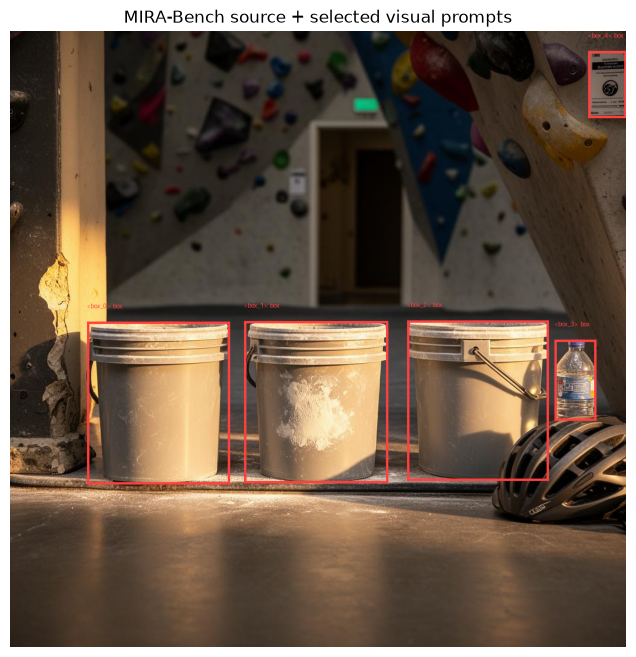

In [2]:
SAMPLE_INDEX = 0
record = records[SAMPLE_INDEX]
sample = load_sample(record, benchmark=BENCHMARK, image_loader=image_loader, prompt_mode=PROMPT_MODE)
if not sample["instruction"]:
    raise ValueError("MIRA-Bench record has no usable original or mixed instruction.")
select_reference_prompts(sample)
print(sample["sample_id"], sample["instruction"])
print("Reference selectors:", [{"token": ref["display_token"], "variable": (ref.get("selected_prompt") or {}).get("variable"), "refers_to": ref["span"], "box": ref["bbox_xyxy"], "point": ref["point_xy"], "scribble": bool(ref["scribble_strokes"])} for ref in sample["references"]])

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(annotate_sample(sample))
ax.set_title("MIRA-Bench source + selected visual prompts")
ax.axis("off")
plt.show()

In [3]:
from framework.tools import image_editing_tools
from evaluation.notebook import create_agent_model

llm = create_agent_model()
tools = image_editing_tools()
print("MIRA-Bench agent ready:", llm.model_id)

MIRA-Bench agent ready: gemini-3.5-flash


In [4]:
SAMPLE_LIMIT = None  # Set to a positive number (e.g. 1) for a smoke test.
if SAMPLE_LIMIT is not None and SAMPLE_LIMIT < 1:
    raise ValueError("SAMPLE_LIMIT must be positive or None.")
SAMPLE_COUNT = len(records) if SAMPLE_LIMIT is None else min(SAMPLE_LIMIT, len(records))
SAMPLE_INDICES = list(range(SAMPLE_COUNT))
SAMPLE_INDICES = [1]
RESUME_LAST_RUN = False  # True continues the latest run and skips completed samples.
from evaluation.notebook import resolve_run_directory

RUN_DIR = resolve_run_directory(OUTPUT_ROOT) if RESUME_LAST_RUN else create_run_directory(OUTPUT_ROOT)
benchmark_results = run_benchmark(
    records,
    SAMPLE_INDICES,
    benchmark=BENCHMARK,
    prompt_mode=PROMPT_MODE,
    output_dir=RUN_DIR,
    image_loader=image_loader,
    model=llm,
    tools=tools,
    resume=RESUME_LAST_RUN,
    display_fn=None,
)
print("Run directory:", RUN_DIR)
print(f"Processed {len(benchmark_results)} of {SAMPLE_COUNT} MIRA-Bench samples.")

Loading weights: 100%|██████████| 1468/1468 [00:00<00:00, 9430.70it/s]=mirage:10.jpg, status=running]
[transformers] `memory_attention_rope_theta` is deprecated and will be removed in v5.0. Use `rope_parameters['rope_theta']` instead.
[transformers] You are using a model of type `sam3_video` to instantiate a model of type `sam3_tracker`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
Loading weights: 100%|██████████| 685/685 [00:00<00:00, 19244.82it/s]
/Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.venv/lib/python3.13/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MES

depth 4


100%|██████████| 4/4 [00:00<00:00, 136.55it/s]
HTTP Request: HEAD https://huggingface.co/fal/flux-2-klein-4B-object-remove-lora/resolve/main/kDEkt5q7tDLKOpQJIVMPx_pytorch_lora_weights_comfy_converted.safetensors "HTTP/1.1 302 Found"
mira_bench inference: 100%|██████████| 1/1 [03:00<00:00, 180.23s/sample, sample=mirage:10.jpg, status=completed]

Run directory: /Users/nghialt3670/Projects/MiMo-Edit/mimo-edit/.out/evaluation/mira_bench/mixed/run_20261017_211151_701377
Processed 1 of 4 MIRA-Bench samples.


In [5]:
completed = [result for result in benchmark_results if result["status"] == "completed"]
failed = [result for result in benchmark_results if result["status"] == "failed"]
print(f"MIRA-Bench samples: {len(benchmark_results)} | completed: {len(completed)} | failed: {len(failed)}")
if benchmark_results:
    print(f"Mean runtime: {sum(result['elapsed_seconds'] for result in benchmark_results) / len(benchmark_results):.2f}s")
print("Review saved outputs and trajectories; runtime/status are not image-quality scores.")

MIRA-Bench samples: 1 | completed: 1 | failed: 0
Mean runtime: 179.79s
Review saved outputs and trajectories; runtime/status are not image-quality scores.
